**Importing Libraries**

In [83]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


**1. Problem Statement**

Objective:
To perform exploratory data analysis on an e-commerce customer dataset to understand behavioral, engagement, and demographic factors that contribute to customer churn.

In [2]:
df=pd.read_csv("ecommerce_customer_churn_dataset.csv")

In [3]:
df

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,38.0,Female,USA,Los Angeles,10.0,10.0,35.8,8.8,51.2,3.0,...,9.2,5.0,1.0,20.7,25.2,1.0,2365.98,3499.0,0,Q2
49996,37.0,Male,USA,Chicago,1.4,21.0,32.4,9.6,32.5,2.0,...,17.6,5.0,3.0,38.6,12.1,4.0,1293.60,3154.0,0,Q3
49997,44.0,Female,USA,Phoenix,2.8,19.0,40.3,10.4,50.6,1.0,...,25.2,4.0,6.0,59.9,NaN,1.0,1655.28,1622.0,0,Q1
49998,41.0,Female,USA,Chicago,2.9,17.0,29.9,10.1,60.8,1.0,...,34.6,5.0,2.0,NaN,14.1,3.0,1286.11,2634.0,0,Q2


**The dataset contains 50,000 customer records with 25 features, including customer demographics, engagement metrics, behavioral indicators, marketing interactions, and a binary churn label.**

**Custumer Churn**

- Customer churn refers to the situation when a customer stops purchasing or becomes inactive with a business over a given period of time.

- In an ecommerce business, a customer is considered churned if they:

- Do not make purchases for a long duration

- Stop engaging with the platform

- Do not return after their last transaction

- Customer churn is usually represented as a binary variable, where:

- 1 = Churned customer

- 0 = Active customer




In [81]:
df.head()

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter,Churned_Num
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1,NaN
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,7.0,3.0,27.6,23.3,3.0,1067.47,3028.0,0,Q4,NaN
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,4.0,1.0,27.6,8.8,2.0,1289.75,2317.0,0,Q4,NaN
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1,NaN
4,35.0,Male,India,Delhi,3.1,29.0,51.4,8.4,19.1,9.0,...,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4,NaN


**Dataset Overview**

- Rows / Records: 50,000 

- Columns / Features: 25 (mix of numerical and categorical)

- Target Variable: Churned (Yes/No)

- Data Types: Numerical, categorical, binary



# Understanding Data

In [4]:
df.shape

(50000, 25)

**Here,There are 50000 rows and 25 columns**

In [5]:
df.dtypes

Age                              float64
Gender                            object
Country                           object
City                              object
Membership_Years                 float64
Login_Frequency                  float64
Session_Duration_Avg             float64
Pages_Per_Session                float64
Cart_Abandonment_Rate            float64
Wishlist_Items                   float64
Total_Purchases                  float64
Average_Order_Value              float64
Days_Since_Last_Purchase         float64
Discount_Usage_Rate              float64
Returns_Rate                     float64
Email_Open_Rate                  float64
Customer_Service_Calls           float64
Product_Reviews_Written          float64
Social_Media_Engagement_Score    float64
Mobile_App_Usage                 float64
Payment_Method_Diversity         float64
Lifetime_Value                   float64
Credit_Balance                   float64
Churned                            int64
Signup_Quarter  

**The dataset contains a mix of numerical and categorical variables.**

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            47505 non-null  float64
 1   Gender                         50000 non-null  object 
 2   Country                        50000 non-null  object 
 3   City                           50000 non-null  object 
 4   Membership_Years               50000 non-null  float64
 5   Login_Frequency                50000 non-null  float64
 6   Session_Duration_Avg           46601 non-null  float64
 7   Pages_Per_Session              47000 non-null  float64
 8   Cart_Abandonment_Rate          50000 non-null  float64
 9   Wishlist_Items                 46000 non-null  float64
 10  Total_Purchases                50000 non-null  float64
 11  Average_Order_Value            50000 non-null  float64
 12  Days_Since_Last_Purchase       47000 non-null 

In [7]:
df.describe()

,Age,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,...,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned
count,47505.000000,50000.000000,50000.000000,46601.000000,47000.000000,50000.000000,46000.000000,50000.000000,50000.000000,47000.000000,...,45509.000000,47472.000000,49832.000000,46500.000000,44000.000000,45000.000000,47500.000000,50000.000000,44500.000000,50000.000000
mean,37.802968,2.984009,11.624660,27.660754,8.737811,57.079973,4.298391,13.111576,123.117330,29.792872,...,6.680913,20.937980,5.681831,2.853312,29.364466,19.371607,2.353874,1440.626292,1966.233258,0.289000
std,11.834668,2.059105,7.810657,10.871013,3.778220,16.282723,3.189754,7.017312,175.569714,29.695062,...,6.143027,14.252561,2.676052,2.328948,20.574021,9.419252,1.110012,907.249443,1225.072166,0.453302
min,5.000000,0.100000,0.000000,1.000000,1.000000,0.000000,0.000000,-13.000000,26.380000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,29.000000,1.400000,6.000000,19.700000,6.000000,46.400000,2.000000,8.000000,87.050000,9.000000,...,2.900000,9.900000,4.000000,1.000000,13.200000,12.500000,2.000000,789.817500,1049.000000,0.000000
50%,38.000000,2.500000,11.000000,26.800000,8.400000,58.100000,4.000000,12.000000,112.970000,21.000000,...,5.400000,19.700000,5.000000,2.000000,27.600000,18.600000,2.000000,1243.415000,1896.000000,0.000000
75%,46.000000,4.000000,17.000000,34.700000,11.200000,68.700000,6.000000,17.000000,144.440000,41.000000,...,9.100000,30.400000,7.000000,4.000000,43.100000,25.500000,3.000000,1874.000000,2791.000000,1.000000
max,200.000000,10.000000,46.000000,75.600000,24.100000,143.743350,28.000000,128.700000,9666.379178,287.000000,...,99.615734,91.700000,21.000000,21.000000,100.000000,61.900000,5.000000,8987.240000,7197.000000,1.000000


# Finding Duplicated values

In [9]:
df.duplicated().sum()

np.int64(0)

## Target Variable Analysis (Churn Distribution)

In [11]:
churn_counts = df['Churned'].value_counts()
churn_percentage = df['Churned'].value_counts(normalize=True) * 100

churn_counts, churn_percentage


(Churned
 0    35550
 1    14450
 Name: count, dtype: int64,
 Churned
 0    71.1
 1    28.9
 Name: proportion, dtype: float64)

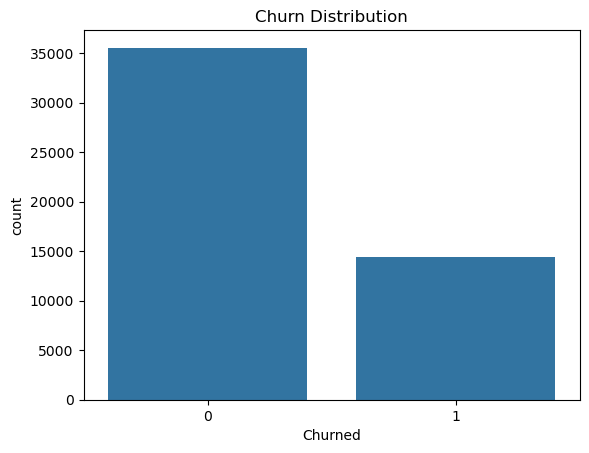

In [84]:

plt.figure()
sns.countplot(x='Churned', data=df)
plt.title("Churn Distribution")
plt.show()


**Churn Distribution Analysis:**
The dataset shows the distribution of churned and non-churned customers. This helps identify whether churn is a common occurrence or limited to a smaller customer segment. Understanding this distribution is important for designing retention strategies and future predictive models.

# Missing values or Null Values

In [17]:
# Check missing values
missing_count = df.isnull().sum()

missing_df = pd.DataFrame({
    'Missing Values': missing_count,
    
})
missing_df[missing_df['Missing Values'] > 0]



,Missing Values
Age,2495
Session_Duration_Avg,3399
Pages_Per_Session,3000
Wishlist_Items,4000
Days_Since_Last_Purchase,3000
Discount_Usage_Rate,3500
Returns_Rate,4491
Email_Open_Rate,2528
Customer_Service_Calls,168
Product_Reviews_Written,3500


### Handling Missing Values

In [23]:
# Separate numerical and categorical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

print(num_cols)
print(cat_cols)

Index(['Age', 'Membership_Years', 'Login_Frequency', 'Session_Duration_Avg',
       'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Wishlist_Items',
       'Total_Purchases', 'Average_Order_Value', 'Days_Since_Last_Purchase',
       'Discount_Usage_Rate', 'Returns_Rate', 'Email_Open_Rate',
       'Customer_Service_Calls', 'Product_Reviews_Written',
       'Social_Media_Engagement_Score', 'Mobile_App_Usage',
       'Payment_Method_Diversity', 'Lifetime_Value', 'Credit_Balance',
       'Churned'],
      dtype='object')
Index(['Gender', 'Country', 'City', 'Signup_Quarter'], dtype='object')


In [24]:
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
df[cat_cols] = df[cat_cols].fillna(df[cat_cols].mode().iloc[0])

In [27]:
df.isnull().sum()

Age                              0
Gender                           0
Country                          0
City                             0
Membership_Years                 0
Login_Frequency                  0
Session_Duration_Avg             0
Pages_Per_Session                0
Cart_Abandonment_Rate            0
Wishlist_Items                   0
Total_Purchases                  0
Average_Order_Value              0
Days_Since_Last_Purchase         0
Discount_Usage_Rate              0
Returns_Rate                     0
Email_Open_Rate                  0
Customer_Service_Calls           0
Product_Reviews_Written          0
Social_Media_Engagement_Score    0
Mobile_App_Usage                 0
Payment_Method_Diversity         0
Lifetime_Value                   0
Credit_Balance                   0
Churned                          0
Signup_Quarter                   0
dtype: int64

**Missing values in numerical features were filled using the median, while categorical features were filled using the most frequent value. This approach avoids data loss and keeps distributions stable.**

## Univariate Analysis (Numerical Features)
To understand the distribution, range, and spread of numerical features in the dataset.

In [28]:
num_features = [
    'Age',
    'Login_Frequency',
    'Session_Duration_Avg',
    'Pages_Per_Session',
    'Purchase_Frequency',
    'Cart_Abandonment_Rate',
    'Lifetime_Value'
]


### Age

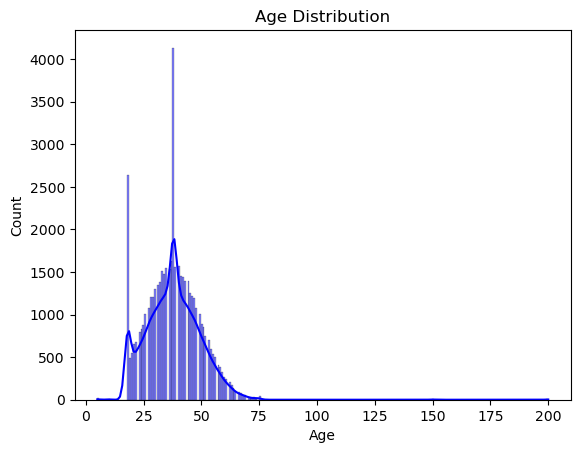

In [43]:
plt.figure()
sns.histplot(df['Age'],color='blue',kde=True)
plt.title("Age Distribution")
plt.show()


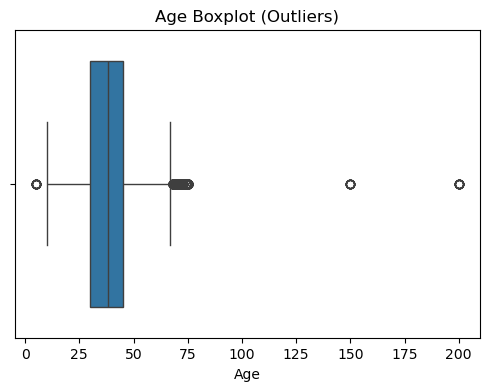

In [53]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['Age'])
plt.title("Age Boxplot (Outliers)")
plt.show()


**obs :**
- Customers have a wide range of ages, indicating a diverse user base.

- Most customers are in the middle age range (you can mention the peak from the histogram).

- A few very young or very old users appear as outliers, but they are valid.

### Login Frequency

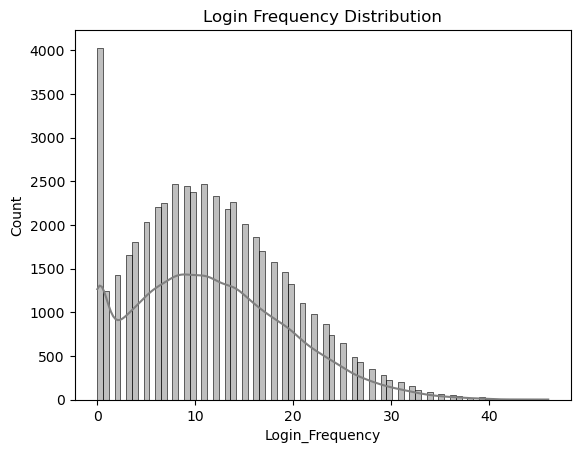

In [45]:
plt.figure()
sns.histplot(df['Login_Frequency'], kde=True,color='Grey')
plt.title("Login Frequency Distribution")
plt.show()


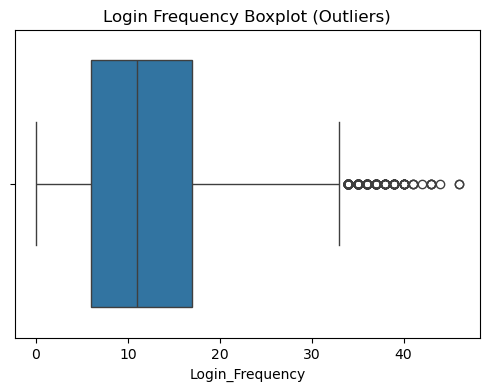

In [54]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['Login_Frequency'])
plt.title("Login Frequency Boxplot (Outliers)")
plt.show()


**obs** :
- Most customers have low to moderate login frequency.

- A few customers login very frequently, showing high engagement.

- Outliers exist, but they represent real user behavior, not errors.

### Session Duration

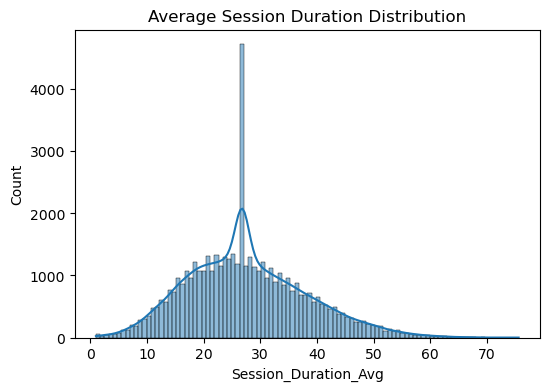

In [55]:
plt.figure(figsize=(6,4))
sns.histplot(df['Session_Duration_Avg'], kde=True)
plt.title("Average Session Duration Distribution")
plt.show()


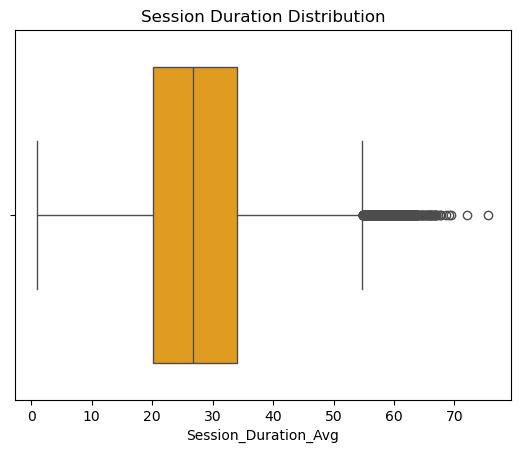

In [56]:
plt.figure()
sns.boxplot(x=df['Session_Duration_Avg'],color='orange')
plt.title("Session Duration Distribution")
plt.show()


**Obs** :
- Most customers have short to moderate session durations, showing typical engagement patterns.

- Some users have very long sessions, which appear as outliers but reflect highly engaged users.

- Understanding session duration helps identify engagement levels that may affect churn.

### Pages_Per_Session

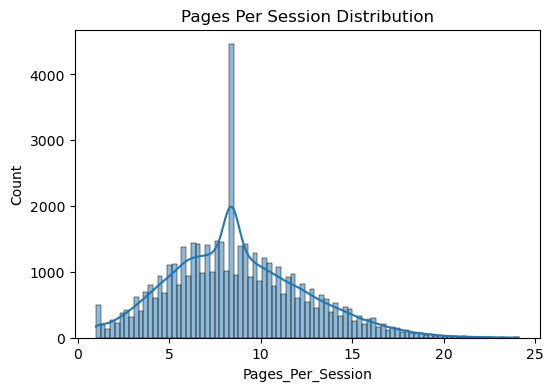

In [57]:
plt.figure(figsize=(6,4))
sns.histplot(df['Pages_Per_Session'], kde=True)
plt.title("Pages Per Session Distribution")
plt.show()


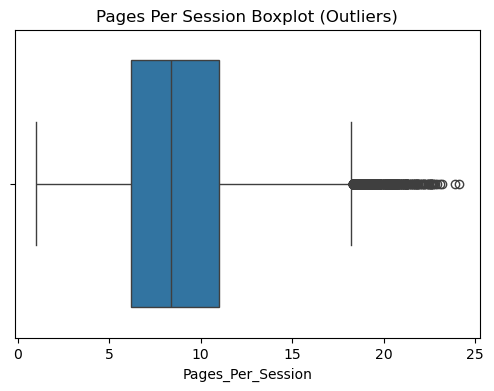

In [58]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['Pages_Per_Session'])
plt.title("Pages Per Session Boxplot (Outliers)")
plt.show()


**Obs** :
- Most customers view a moderate number of pages per session, indicating normal browsing behavior.

- A few users visit many pages in a session, appearing as outliers but showing highly engaged behavior.

- This feature helps understand user exploration and engagement on the platform.

### Cart_Abandonment_Rate

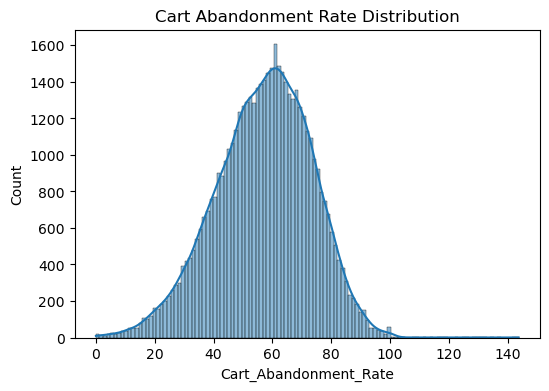

In [59]:
plt.figure(figsize=(6,4))
sns.histplot(df['Cart_Abandonment_Rate'], kde=True)
plt.title("Cart Abandonment Rate Distribution")
plt.show()


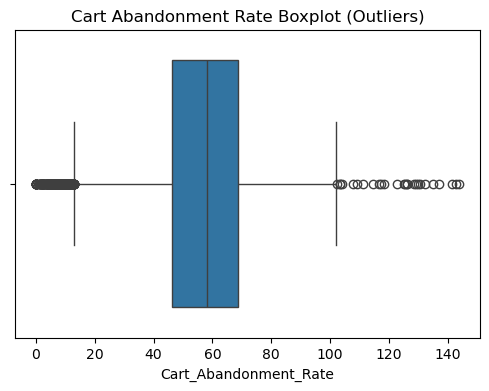

In [60]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['Cart_Abandonment_Rate'])
plt.title("Cart Abandonment Rate Boxplot (Outliers)")
plt.show()


**Obs** :
- Most customers have a low to moderate cart abandonment rate, indicating normal shopping behavior.

- Some customers have very high abandonment rates, appearing as outliers but reflecting real user patterns.

- High cart abandonment may signal frustration or indecision, which can lead to churn.

### Lifetime_Value

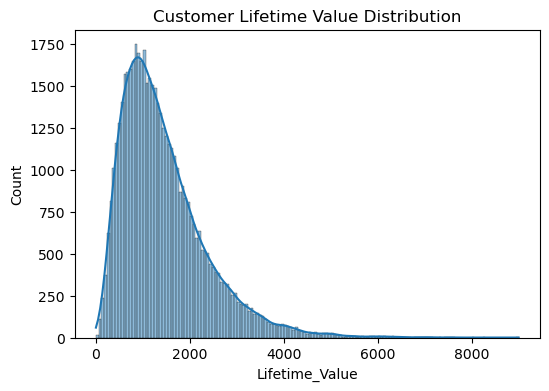

In [61]:
plt.figure(figsize=(6,4))
sns.histplot(df['Lifetime_Value'], kde=True)
plt.title("Customer Lifetime Value Distribution")
plt.show()


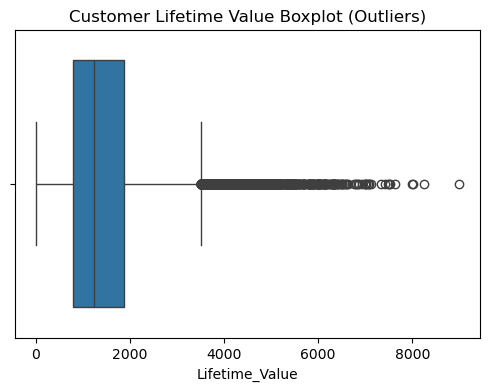

In [62]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['Lifetime_Value'])
plt.title("Customer Lifetime Value Boxplot (Outliers)")
plt.show()


**Obs** :
- Most customers have a low to moderate lifetime value, representing typical spending patterns.

- A few customers have very high lifetime value, appearing as outliers but showing high-value users.

- Understanding lifetime value is critical for prioritizing retention efforts.



### Credit_Balance

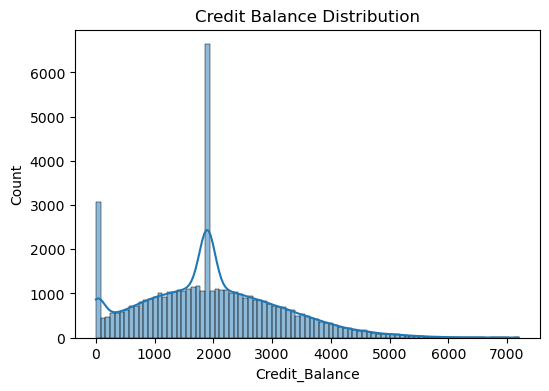

In [64]:
plt.figure(figsize=(6,4))
sns.histplot(df['Credit_Balance'], kde=True)
plt.title("Credit Balance Distribution")
plt.show()


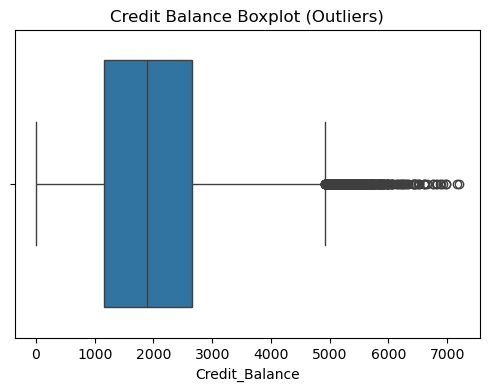

In [65]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['Credit_Balance'])
plt.title("Credit Balance Boxplot (Outliers)")
plt.show()


**Obs** :
- Most customers have a low to moderate credit balance, reflecting typical account usage.

- A few customers have very high balances, appearing as outliers but representing real high-value users.

- Credit balance is useful for understanding financial engagement and potential loyalty.

# Bi_variate Analysis

###  Churn vs Categorical

### Gender vs Churn

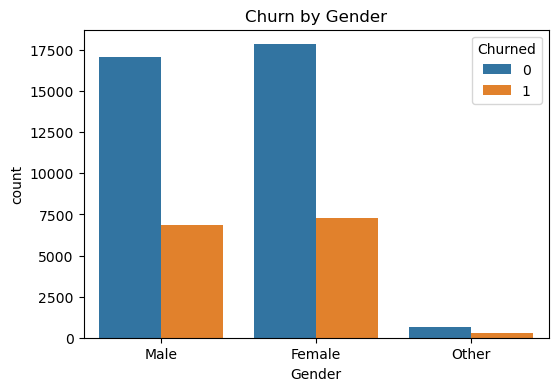

In [66]:
plt.figure(figsize=(6,4))
sns.countplot(x='Gender', hue='Churned', data=df)
plt.title("Churn by Gender")
plt.show()


### Country vs Churn

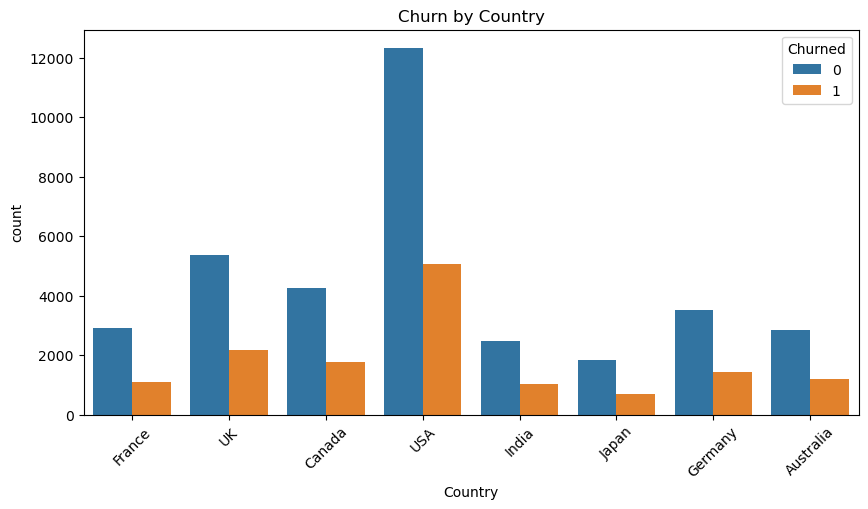

In [67]:
plt.figure(figsize=(10,5))
sns.countplot(x='Country', hue='Churned', data=df)
plt.title("Churn by Country")
plt.xticks(rotation=45)
plt.show()


**obs** :
-“Customers from  USA show higher churn, suggesting regional factors may affect retention.”

### Payment_Method_Diversity vs Churn.

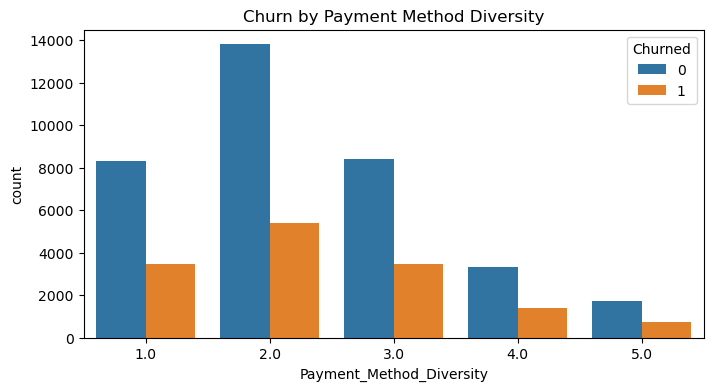

In [69]:
plt.figure(figsize=(8,4))
sns.countplot(x='Payment_Method_Diversity', hue='Churned', data=df)
plt.title("Churn by Payment Method Diversity")
plt.show()


**“Customers with only one payment method tend to churn more than those using multiple methods.”**

# Churn vs Numerical Features

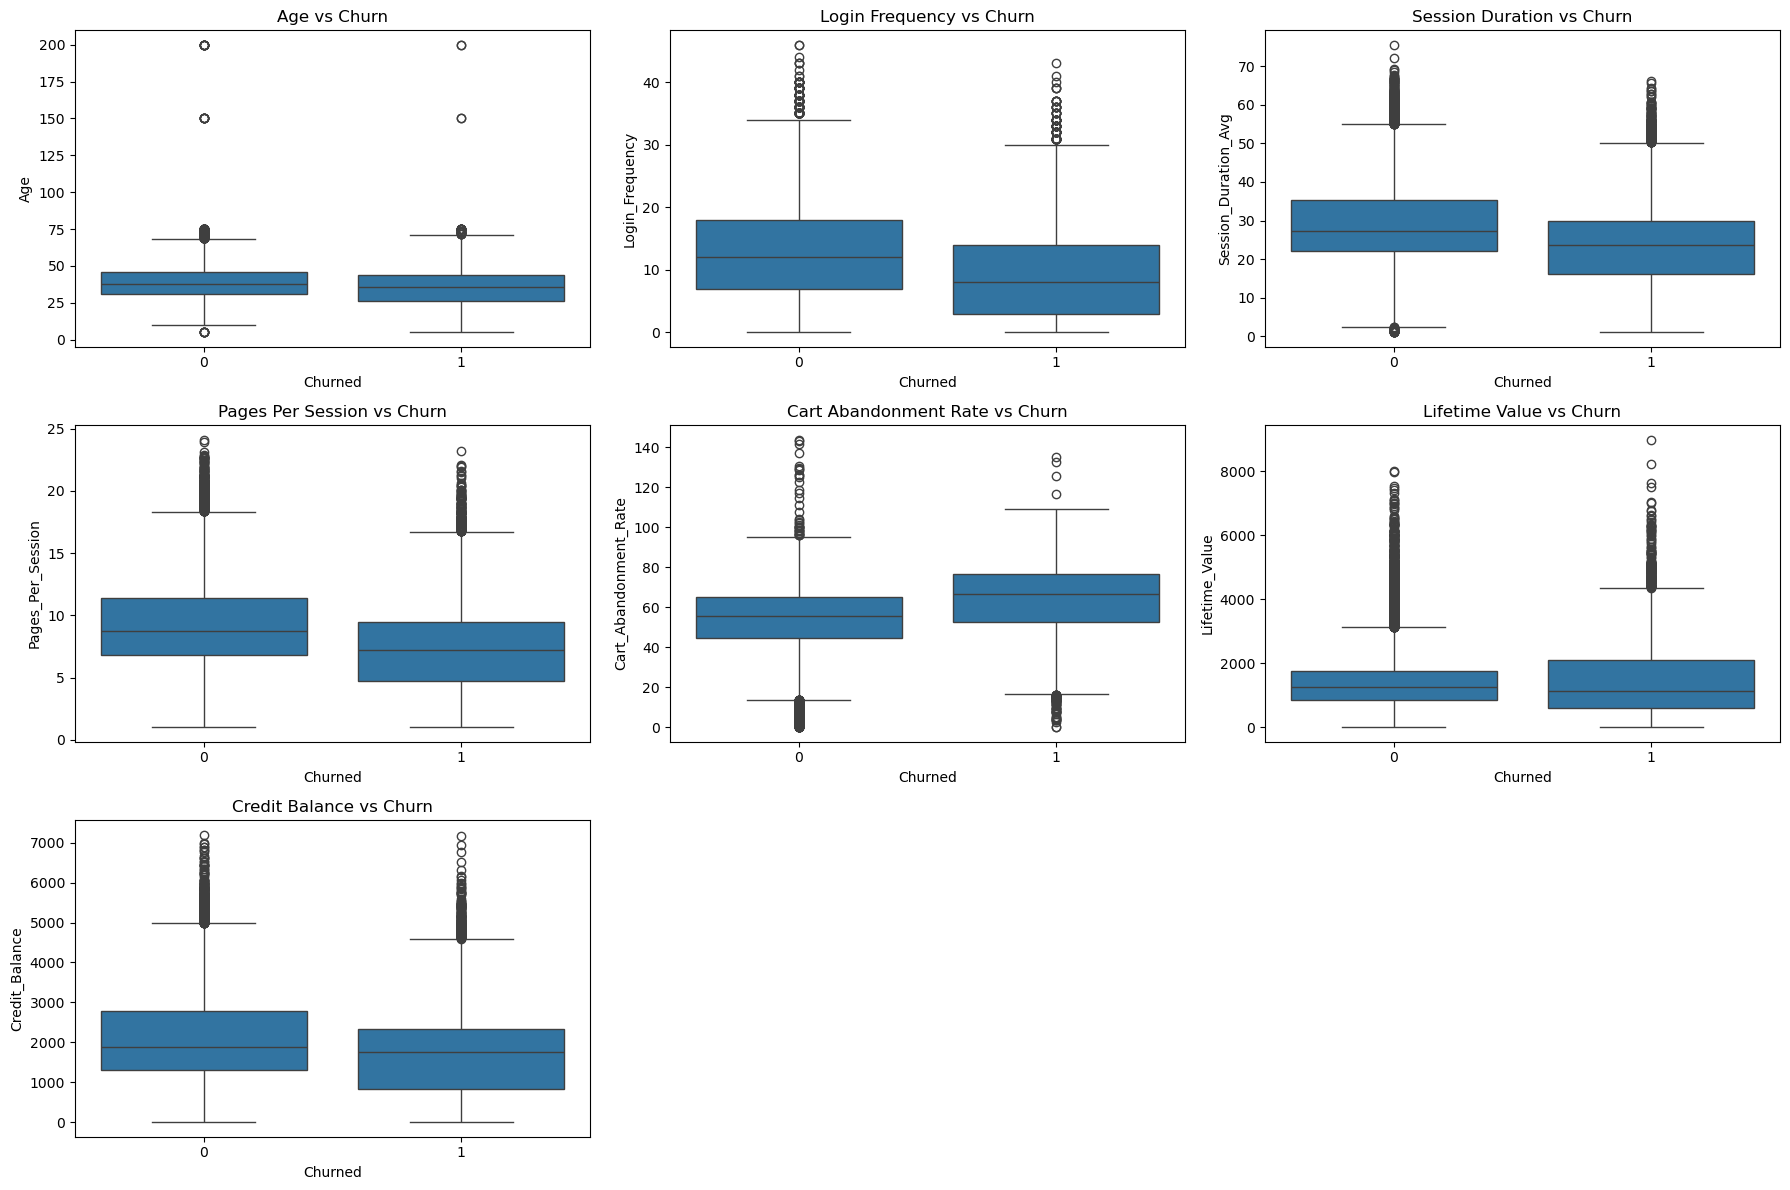

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 3, figsize=(18, 12))

# Row 1
sns.boxplot(x='Churned', y='Age', data=df, ax=axes[0,0])
axes[0,0].set_title("Age vs Churn")

sns.boxplot(x='Churned', y='Login_Frequency', data=df, ax=axes[0,1])
axes[0,1].set_title("Login Frequency vs Churn")

sns.boxplot(x='Churned', y='Session_Duration_Avg', data=df, ax=axes[0,2])
axes[0,2].set_title("Session Duration vs Churn")

# Row 2
sns.boxplot(x='Churned', y='Pages_Per_Session', data=df, ax=axes[1,0])
axes[1,0].set_title("Pages Per Session vs Churn")

sns.boxplot(x='Churned', y='Cart_Abandonment_Rate', data=df, ax=axes[1,1])
axes[1,1].set_title("Cart Abandonment Rate vs Churn")

sns.boxplot(x='Churned', y='Lifetime_Value', data=df, ax=axes[1,2])
axes[1,2].set_title("Lifetime Value vs Churn")

# Row 3
sns.boxplot(x='Churned', y='Credit_Balance', data=df, ax=axes[2,0])
axes[2,0].set_title("Credit Balance vs Churn")

# Remove empty subplots
fig.delaxes(axes[2,1])
fig.delaxes(axes[2,2])

plt.tight_layout()
plt.show()


**Observations :**

- Churned users have lower login frequency and session duration.

- Churned users have higher cart abandonment.

- Retained customers have higher lifetime value and credit balance.

- Age differences are minimal; engagement and behavior are stronger churn indicators.

# multivariate analysis

## Correlation Heatmap

In [79]:
corr_matrix = df[num_features].corr()
corr_matrix

,Age,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Lifetime_Value,Credit_Balance
Age,1.000000,-0.004155,-0.001409,0.001133,0.000089,-0.001413,-0.004351
Login_Frequency,-0.004155,1.000000,0.685319,0.654605,-0.624929,0.499324,0.476917
Session_Duration_Avg,-0.001409,0.685319,1.000000,0.714086,-0.677323,0.541683,0.518605
Pages_Per_Session,0.001133,0.654605,0.714086,1.000000,-0.648117,0.515333,0.495290
Cart_Abandonment_Rate,0.000089,-0.624929,-0.677323,-0.648117,1.000000,-0.495295,-0.469764
Lifetime_Value,-0.001413,0.499324,0.541683,0.515333,-0.495295,1.000000,0.378661
Credit_Balance,-0.004351,0.476917,0.518605,0.495290,-0.469764,0.378661,1.000000


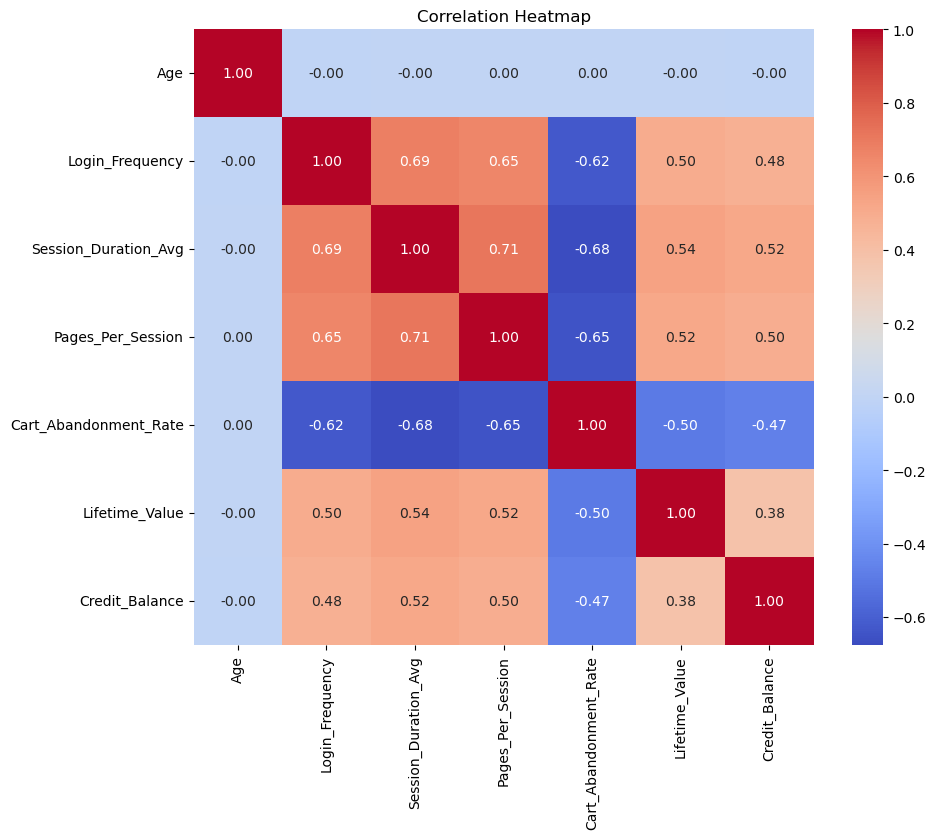

In [80]:
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


**Observations**
- Cart_Abandonment_Rate is positively correlated with churn (higher abandonment → higher churn).

- Login_Frequency, Session_Duration_Avg, Lifetime_Value, Credit_Balance are negatively correlated with churn (higher engagement → lower churn).

- Age and Pages_Per_Session show weak correlation with churn.

- This heatmap helps identify the most important features for predicting churn.

## Key Findings
**1. Target Variable (Churn)**

- Majority of customers are retained, but a noticeable portion churned, highlighting retention challenges.

- Class imbalance exists, typical in real-world e-commerce datasets.

**2. Numerical Features**

- Engagement metrics (Login Frequency, Session Duration) are lower for churned users.

- Cart Abandonment Rate is higher for churned customers.

- Lifetime Value and Credit Balance are higher for retained customers.

- Age and Pages per Session show minimal differences.

- Outliers are present in many features but represent real customer behavior, so they were retained.

**3. Categorical Features**

- Gender: Small differences observed in churn.

- Country/City: Certain regions have higher churn rates.

- Payment Method Diversity: Customers with fewer payment options churn more.

- Signup Quarter: Seasonal differences in churn observed.

**4. Correlation Analysis**

- Positive correlation: Cart Abandonment Rate → Churn

- Negative correlation: Login Frequency, Session Duration, Lifetime Value, Credit Balance → Churn

- Weak correlation: Age, Pages per Session

## Business Insights

- **Engagement is critical:** Customers with low login frequency or short session duration are more likely to churn.

- **High-value customers:** Retained customers typically have higher lifetime value and credit balance — prioritize their retention.

- **Behavioral signals:** High cart abandonment predicts churn — interventions like reminders or discounts can help.

- **Demographics & region:** Minor influence, but targeted campaigns by country/city can improve retention.